In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import sys
import math

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## dapo-fig2

**Figure 2: Accuracy on AIME (avg@32) over training with and without Clip-Higher.** Dashed lines mark each run's best accuracy. With Clip-Higher, accuracy peaks at 0.406, against 0.269 without it.

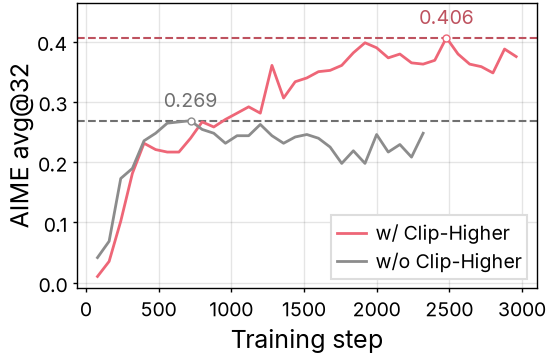

In [2]:
with open("../data/dapo.json") as f:
    runs = json.load(f)["fig2a"]

fig, ax = plt.subplots(figsize=(2.75, 2))
for name, color in [("w/ Clip-Higher", colors["ours"]), ("w/o Clip-Higher", colors["neutral"])]:
    steps, values = runs[name]["step"], runs[name]["value"]
    ax.plot(steps, values, color=color, label=name)
    best = int(np.argmax(values))
    mark_value(ax, steps[best], values[best], f"{values[best]:.3g}", color)
ax.set_xlabel("Training step")
ax.set_ylabel("AIME avg@32")
ax.legend(loc="lower right")
fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/dapo-fig2.pdf")
fig.savefig("../outputs/dapo-fig2.png")
plt.show()

## dapo-fig6

**Figure 6: Accuracy on AIME (avg@32) over training of a baseline setting before and after applying dynamic sampling.** Dashed lines mark each run's best accuracy. With dynamic sampling, accuracy peaks at 0.438 by step 2320, while without it the best is 0.421, reached only at step 6240.

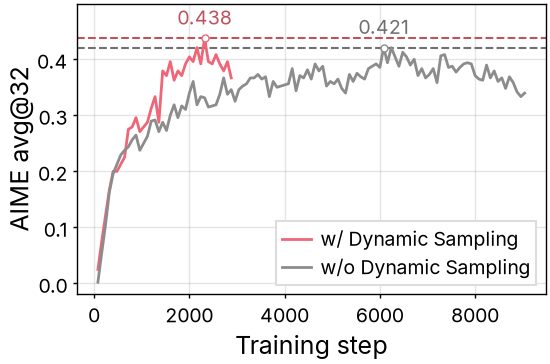

In [3]:
with open("../data/dapo.json") as f:
    runs = json.load(f)["fig6"]

fig, ax = plt.subplots(figsize=(2.75, 2))
for name, color in [("w/ Dynamic Sampling", colors["ours"]), ("w/o Dynamic Sampling", colors["neutral"])]:
    steps, values = runs[name]["step"], runs[name]["value"]
    ax.plot(steps, values, color=color, label=name)
    best = int(np.argmax(values))
    mark_value(ax, steps[best], values[best], f"{values[best]:.3g}", color)
ax.set_xlabel("Training step")
ax.set_ylabel("AIME avg@32")
ax.legend(loc="lower right")
fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/dapo-fig6.pdf")
fig.savefig("../outputs/dapo-fig6.png")
plt.show()

## rlvr-fig2

**Figure 2: Pass@k of base models and their RLVR-trained counterparts on four mathematical benchmarks.** Rows are benchmarks and columns are models; the x axis is log₂-scaled, and dashed lines mark the pass@k at k = 128 for Qwen2.5-32B on Minerva. RL-trained models lead at small k (Qwen2.5-32B on Minerva: 0.434 vs. 0.275 at k = 1), but base models catch up and surpass them as k grows (0.676 vs. 0.585 at k = 128).

/Users/owj0421/Desktop/working/academic-figure-skill/examples/use-cases/notebooks/../../../skills/academic-figure/assets/paper.py:198: UserWarning: panel 'Qwen2.5-7B' is narrower than 1.2 in; use one column fewer
  warnings.warn(f"panel {a.get_title()!r} is narrower than 1.2 in; use one column fewer")
/Users/owj0421/Desktop/working/academic-figure-skill/examples/use-cases/notebooks/../../../skills/academic-figure/assets/paper.py:198: UserWarning: panel 'Qwen2.5-14B' is narrower than 1.2 in; use one column fewer
  warnings.warn(f"panel {a.get_title()!r} is narrower than 1.2 in; use one column fewer")
/Users/owj0421/Desktop/working/academic-figure-skill/examples/use-cases/notebooks/../../../skills/academic-figure/assets/paper.py:198: UserWarning: panel 'Qwen2.5-32B' is narrower than 1.2 in; use one column fewer
  warnings.warn(f"panel {a.get_title()!r} is narrower than 1.2 in; use one column fewer")
/Users/owj0421/Desktop/working/academic-figure-skill/examples/use-cases/notebooks/../../.

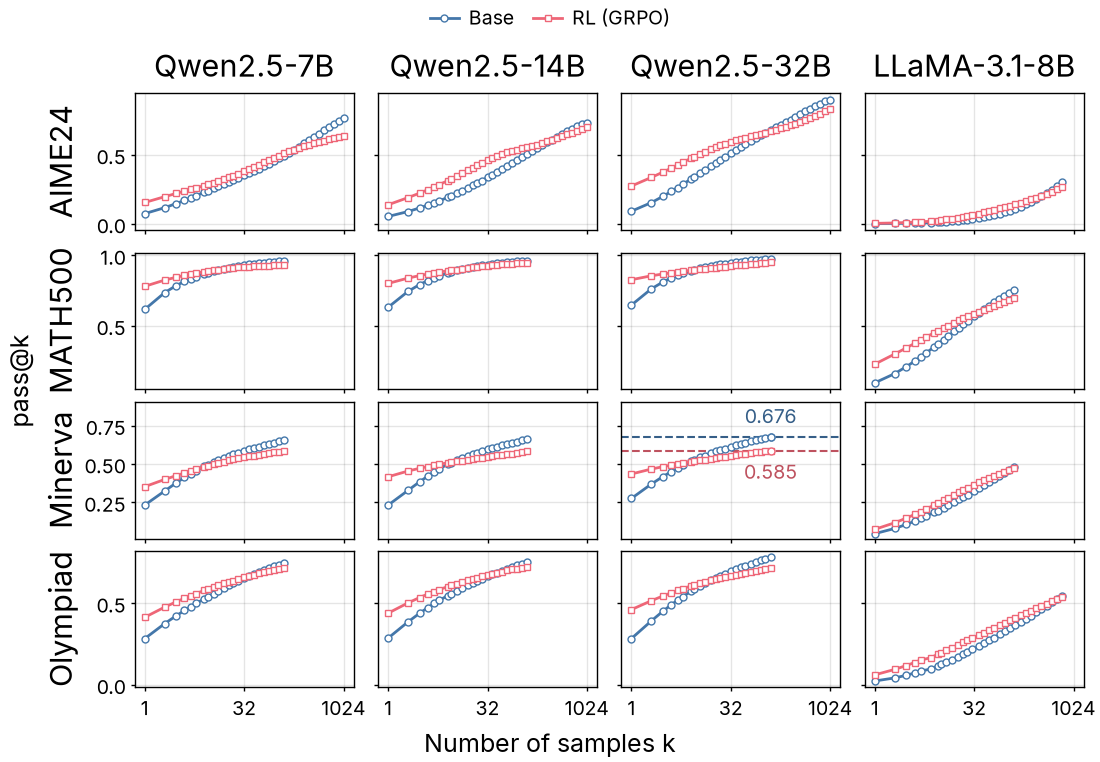

In [4]:
data = json.load(open("../data/rlvr.json"))
benchmarks = ["AIME24", "MATH500", "Minerva", "Olympiad"]
models = ["Qwen2.5-7B", "Qwen2.5-14B", "Qwen2.5-32B", "LLaMA-3.1-8B"]
series = [("Base", "Base", colors["series-1"], "o"), ("RL", "RL (GRPO)", colors["series-2"], "s")]

fig, axes = plt.subplots(4, 4, figsize=(5.5, 5), sharex="col", sharey="row")
for r, benchmark in enumerate(benchmarks):
    for c, model in enumerate(models):
        ax = axes[r, c]
        for key, label, color, marker in series:
            curve = data[benchmark][model][key]
            ax.plot(curve["k"], curve["pass"], marker + "-", color=color, label=label)
        ax.set_xscale("log", base=2)
        if r == 0:
            ax.set_title(model)
    axes[r, 0].annotate(benchmark, xy=(0, 0.5), xycoords="axes fraction", xytext=(-20, 0),
                        textcoords="offset points", ha="right", va="center", rotation=90, fontsize=11)

base, rl = data["Minerva"]["Qwen2.5-32B"]["Base"], data["Minerva"]["Qwen2.5-32B"]["RL"]
mark_value(axes[2, 2], base["k"][-1], base["pass"][-1], f"{base['pass'][-1]:.3f}", colors["series-1"])
mark_value(axes[2, 2], rl["k"][-1], rl["pass"][-1], f"{rl['pass'][-1]:.3f}", colors["series-2"], below=True)

top = 1024
ks = [1, 32, 1024]
margin = 2 ** (0.05 * math.log2(top))
for ax in axes[-1]:
    ax.set_xticks(ks, labels=[str(k) for k in ks])
    ax.set_xticks([], minor=True)
    ax.set_xlim(1 / margin, top * margin)
fig.supxlabel("Number of samples k")
fig.supylabel("pass@k")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=2, frameon=False, borderaxespad=0)

fit_height(fig, axes, aspect=0.618)
fig.savefig("../outputs/rlvr-fig2.pdf")
fig.savefig("../outputs/rlvr-fig2.png")
plt.show()

## rlvr-fig5

**Figure 5: Distribution of per-problem accuracy on Minerva (272 problems) for Qwen2.5-7B before and after RLVR training (SimpleRL-Zoo).** RLVR raises the number of problems solved with accuracy 1.0 from 3 to 47 and lowers the counts in the low-accuracy bins (e.g. 52 → 33 in (0.0, 0.1]), but it also raises the number of unsolved problems at accuracy 0 from 93 to 113.

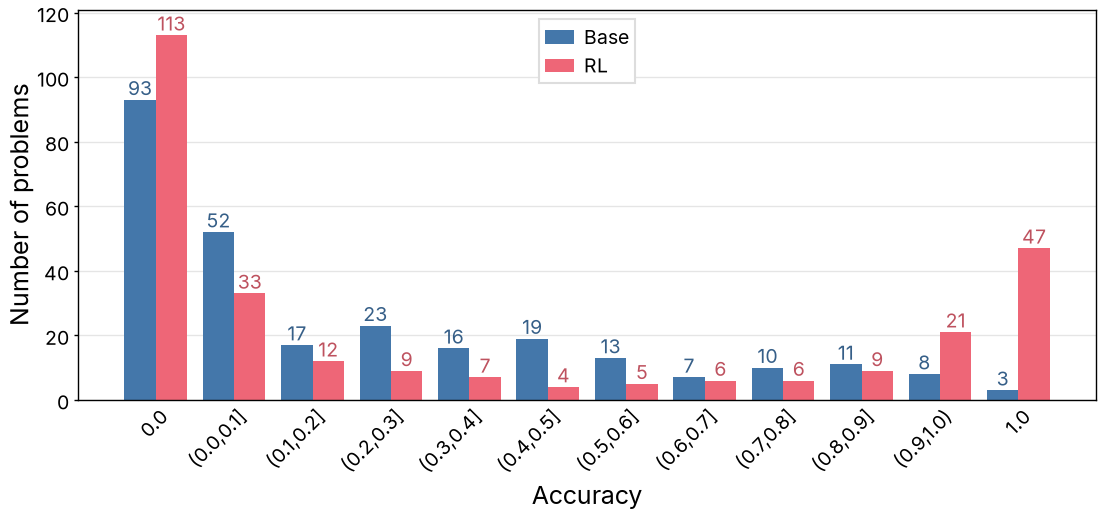

In [5]:
with open("../data/rlvr-fig5.json") as f:
    counts = json.load(f)

x = np.arange(len(counts["bins"]))
width = 0.8 / 2
fig, ax = plt.subplots(figsize=(5.5, 2))
for i, (name, color) in enumerate([("Base", colors["series-1"]), ("RL", colors["series-2"])]):
    bars = ax.bar(x + (i - 0.5) * width, counts[name], width, color=color, linewidth=0, label=name)
    ax.bar_label(bars, fmt="%.3g", color=darken(color))
ax.set_xticks(x, labels=counts["bins"], rotation=45, ha="right", rotation_mode="anchor")
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Accuracy")
ax.set_ylabel("Number of problems")
ax.legend(loc="upper center")
fit_height(fig, ax, aspect=0.382)
fig.savefig("../outputs/rlvr-fig5.pdf")
fig.savefig("../outputs/rlvr-fig5.png")
plt.show()

## rlvr-fig6

**Figure 6: Perplexity of individual responses to an AIME24 problem under Qwen2.5-7B-Base and its RL-trained version.** PPL_A(Y_B) is model A's perplexity on model B's responses, each point is one response (16 per model, 7 from OpenAI-o1 for Y_GT), boxes span the quartiles with the median as a line, and whiskers reach 1.5× the interquartile range. The base model's perplexity on RL responses (median 1.056) lies in the lower part of its perplexity on its own responses (median 1.084, range 1.027–1.126), so the RL model's responses are ones the base model already tends to generate.

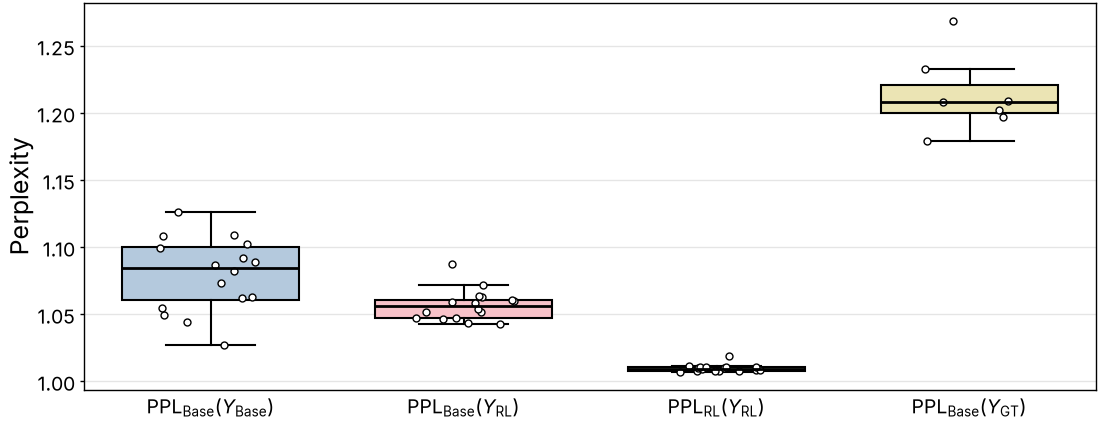

In [6]:
with open("../data/rlvr-fig6.json") as f:
    perplexities = json.load(f)["Problem 1"]

groups = [
    ("PPL_Base(Y_Base)", r"$\mathrm{PPL}_{\mathrm{Base}}(Y_{\mathrm{Base}})$", colors["series-1"]),
    ("PPL_Base(Y_RL)", r"$\mathrm{PPL}_{\mathrm{Base}}(Y_{\mathrm{RL}})$", colors["series-2"]),
    ("PPL_RL(Y_RL)", r"$\mathrm{PPL}_{\mathrm{RL}}(Y_{\mathrm{RL}})$", colors["series-3"]),
    ("PPL_Base(Y_GT)", r"$\mathrm{PPL}_{\mathrm{Base}}(Y_{\mathrm{GT}})$", colors["series-4"]),
]
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(5.5, 2))
for x, (key, label, color) in enumerate(groups):
    values = perplexities[key]
    box = ax.boxplot(values, positions=[x], widths=0.7, showfliers=False)
    box["boxes"][0].set_facecolor(lighten(color))
    ax.plot(x + rng.uniform(-0.2, 0.2, len(values)), values, "o", color="black", markerfacecolor="white", linestyle="none")
ax.set_xticks(range(len(groups)), labels=[label for _, label, _ in groups])
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Perplexity")
fit_height(fig, ax, aspect=0.382)
fig.savefig("../outputs/rlvr-fig6.pdf")
fig.savefig("../outputs/rlvr-fig6.png")
plt.show()